# Dibuja y aprende: reconocimiento de dibujos para aprender vocabulario en inglés
## Paso 1 — Datos

**Idea:** una app para quienes están empezando con el inglés y prefieren aprender creando: la persona ve una palabra, la dibuja y la IA reconoce qué dibujó. Se apoya en el *efecto del dibujo* (dibujar una palabra ayuda a recordarla mejor que escribirla; Wammes, Meade y Fernandes, 2016).

**Vocabulario:** 40 palabras básicas en 5 temas (frutas y comida, animales, casa y objetos, naturaleza, transporte).

**Datos:** *Quick, Draw!* de Google (CC BY 4.0). Cada dibujo se guarda como trazos (coordenadas en orden), con el país del jugador y si el juego lo reconoció o no.

**Qué sale de este paso**
- Imágenes de 28×28 para SVM, ANN, CNN y transfer learning.
- Secuencias de trazos para la LSTM.
- Dos pruebas especiales: dibujos hechos en **Colombia** y dibujos que **el juego no reconoció** (los más difíciles).

## 1. Configuración

In [1]:
import os, json, random, subprocess, sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# 40 palabras en 5 temas: inglés -> español. Hay parejas parecidas a propósito (manzana/pera, gato/perro/conejo)
TEMAS = {
    "Frutas y comida": {"apple": "manzana", "pear": "pera", "banana": "banano", "strawberry": "fresa",
                        "watermelon": "sandía", "grapes": "uvas", "ice cream": "helado", "pizza": "pizza"},
    "Animales": {"cat": "gato", "dog": "perro", "rabbit": "conejo", "bird": "pájaro", "butterfly": "mariposa",
                 "fish": "pez", "snake": "serpiente", "cow": "vaca", "frog": "rana", "elephant": "elefante"},
    "Casa y objetos": {"house": "casa", "umbrella": "sombrilla", "guitar": "guitarra", "chair": "silla",
                       "cup": "taza", "clock": "reloj", "book": "libro", "key": "llave"},
    "Naturaleza": {"tree": "árbol", "flower": "flor", "sun": "sol", "moon": "luna",
                   "cloud": "nube", "rainbow": "arcoíris", "mountain": "montaña"},
    "Transporte": {"car": "carro", "bicycle": "bicicleta", "bus": "bus", "airplane": "avión",
                   "sailboat": "velero", "train": "tren", "truck": "camión"},
}
PALABRAS = {p: e for tema in TEMAS.values() for p, e in tema.items()}
CLASES = list(PALABRAS)

N_RECONOCIDOS = 8000   # dibujos reconocidos por palabra (para entrenar, validar y probar)
N_NO_RECONOCIDOS = 1000  # dibujos NO reconocidos por palabra (prueba difícil)
PAIS = "CO"            # dibujos de Colombia (prueba aparte)

BASE = Path("/content")
CRUDOS = BASE / "quickdraw_ndjson"
CRUDOS.mkdir(parents=True, exist_ok=True)
BORRAR_CRUDOS = True   # borrar cada archivo después de procesarlo para ahorrar disco

## 2. Funciones de dibujo

Este archivo se usa **igual** en el entrenamiento y en la app. Si la app preparara el dibujo de otra forma, el modelo fallaría aunque esté bien entrenado.

- `dibujar`: centra el dibujo, lo traza en un lienzo de 256×256 y lo reduce a 28×28.
- `a_secuencia`: convierte los trazos en una secuencia de movimientos para la LSTM.

In [2]:
%%writefile dibujos.py
"""Funciones compartidas: se usan IGUAL en el entrenamiento y en la app.

Un dibujo es una lista de trazos; cada trazo es [xs, ys] (coordenadas de los puntos).
"""
import numpy as np
from PIL import Image, ImageDraw

LIENZO = 256      # se dibuja primero en grande y luego se reduce
MARGEN = 24       # espacio libre alrededor del dibujo
GROSOR = 14       # grosor del trazo en el lienzo grande
LADO = 28         # tamaño final de la imagen (28x28)
MAX_PUNTOS = 128  # largo máximo de la secuencia para la LSTM


def normalizar_trazos(trazos):
    """Lleva el dibujo a la esquina (mínimo 0) y escala el lado mayor a 255,
    igual que el formato 'simplified' de Quick Draw."""
    trazos = [t for t in trazos if len(t[0]) > 0]
    xs = np.concatenate([np.asarray(t[0], dtype=float) for t in trazos])
    ys = np.concatenate([np.asarray(t[1], dtype=float) for t in trazos])
    minx, miny = xs.min(), ys.min()
    escala = 255.0 / max(xs.max() - minx, ys.max() - miny, 1.0)
    return [[(np.asarray(t[0], float) - minx) * escala,
             (np.asarray(t[1], float) - miny) * escala] for t in trazos]


def dibujar(trazos, lado=LADO):
    """Convierte los trazos en una imagen lado x lado (fondo negro, trazo blanco),
    con el dibujo centrado."""
    t = normalizar_trazos(trazos)
    ancho = max(x.max() for x, _ in t)
    alto = max(y.max() for _, y in t)
    util = LIENZO - 2 * MARGEN
    s = util / 255.0
    dx = MARGEN + (util - ancho * s) / 2
    dy = MARGEN + (util - alto * s) / 2

    img = Image.new("L", (LIENZO, LIENZO), 0)
    d = ImageDraw.Draw(img)
    r = GROSOR / 2
    for x, y in t:
        puntos = list(zip(x * s + dx, y * s + dy))
        if len(puntos) == 1:
            px, py = puntos[0]
            d.ellipse([px - r, py - r, px + r, py + r], fill=255)
        else:
            d.line(puntos, fill=255, width=GROSOR, joint="curve")
            for px, py in (puntos[0], puntos[-1]):   # puntas redondeadas
                d.ellipse([px - r, py - r, px + r, py + r], fill=255)
    return np.asarray(img.resize((lado, lado), Image.LANCZOS), dtype=np.uint8)


def a_secuencia(trazos, max_puntos=MAX_PUNTOS):
    """Convierte los trazos en una secuencia para la LSTM.
    Cada paso: [dx, dy, fin_de_trazo, 1]. El último 1 marca que el paso existe
    (los pasos de relleno quedan en 0 y la LSTM los ignora con Masking)."""
    t = normalizar_trazos(trazos)
    puntos = []
    for x, y in t:
        n = len(x)
        for i in range(n):
            puntos.append([x[i] / 255.0, y[i] / 255.0, 1.0 if i == n - 1 else 0.0])
    p = np.array(puntos, dtype=np.float32)
    seq = p.copy()
    seq[1:, :2] = p[1:, :2] - p[:-1, :2]          # desplazamientos entre puntos
    largo = len(seq)
    seq = seq[:max_puntos]
    salida = np.zeros((max_puntos, 4), dtype=np.float32)
    salida[:len(seq), :3] = seq
    salida[:len(seq), 3] = 1.0
    return salida, largo


Writing dibujos.py


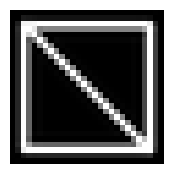

In [3]:
import importlib, dibujos
importlib.reload(dibujos)
from dibujos import dibujar, a_secuencia, MAX_PUNTOS

# Prueba rápida con un cuadrado y una diagonal
prueba = [[[0, 100, 100, 0, 0], [0, 0, 100, 100, 0]], [[0, 100], [0, 100]]]
plt.figure(figsize=(2, 2)); plt.imshow(dibujar(prueba), cmap="gray"); plt.axis("off"); plt.show()

## 3. Descarga y muestreo

Se descarga un archivo por palabra (formato *simplified*). De cada archivo se toman:
- Todos los dibujos de **Colombia** (se apartan antes del muestreo para que no se repitan en entrenamiento).
- Una muestra al azar de dibujos **reconocidos** de otros países.
- Una muestra al azar de dibujos **no reconocidos** de otros países.

In [4]:
URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/{}.ndjson"

def descargar(palabra):
    ruta = CRUDOS / f"{palabra}.ndjson"
    if not ruta.exists():
        url = URL.format(palabra.replace(" ", "%20"))
        subprocess.run(["wget", "-q", "-O", str(ruta), url], check=True)
    return ruta

def procesar(dibujo, etiqueta, grupo):
    img = dibujar(dibujo["drawing"])
    seq, largo = a_secuencia(dibujo["drawing"])
    return img, seq, largo, etiqueta, grupo, dibujo.get("countrycode", ""), len(dibujo["drawing"])

registros, stats = [], []
for etiqueta, palabra in enumerate(tqdm(CLASES, desc="Palabras")):
    ruta = descargar(palabra)
    reco, no_reco, colombia = [], [], []
    paises = Counter()
    with open(ruta) as f:
        for linea in f:
            d = json.loads(linea)
            paises[d.get("countrycode", "")] += 1
            if d.get("countrycode") == PAIS:
                colombia.append(d)
            elif d["recognized"]:
                reco.append(d)
            else:
                no_reco.append(d)

    total = len(reco) + len(no_reco) + len(colombia)
    stats.append({
        "palabra": palabra, "español": PALABRAS[palabra], "total": total,
        "% reconocidos": round(100 * (len(reco) + sum(c["recognized"] for c in colombia)) / total, 1),
        "Colombia": len(colombia),
        "países": len(paises),
    })

    rng = random.Random(SEED + etiqueta)
    for d in rng.sample(reco, min(N_RECONOCIDOS, len(reco))):
        registros.append(procesar(d, etiqueta, "principal"))
    for d in rng.sample(no_reco, min(N_NO_RECONOCIDOS, len(no_reco))):
        registros.append(procesar(d, etiqueta, "no_reconocido"))
    for d in colombia:
        registros.append(procesar(d, etiqueta, "colombia_" + ("reco" if d["recognized"] else "no_reco")))

    del reco, no_reco, colombia
    if BORRAR_CRUDOS:
        ruta.unlink()

tabla_stats = pd.DataFrame(stats).set_index("palabra")
tabla_stats

Palabras:   0%|          | 0/40 [00:00<?, ?it/s]

,español,total,% reconocidos,Colombia,países
palabra,,,,,
apple,manzana,144722,96.7,204,179
pear,pera,116904,97.9,169,177
banana,banano,307936,92.9,421,190
strawberry,fresa,122301,96.9,181,176
watermelon,sandía,132939,93.6,182,178
grapes,uvas,155305,92.3,200,180
ice cream,helado,123133,97.3,158,173
pizza,pizza,130371,95.4,179,179
cat,gato,123202,83.6,172,173


In [5]:
X = np.stack([r[0] for r in registros])
S = np.stack([r[1] for r in registros])
largos = np.array([r[2] for r in registros])
y = np.array([r[3] for r in registros])
grupo = np.array([r[4] for r in registros])
pais = np.array([r[5] for r in registros])
n_trazos = np.array([r[6] for r in registros])
del registros

print("Imágenes:", X.shape, "| Secuencias:", S.shape)
print(pd.Series(grupo).value_counts())

Imágenes: (367732, 28, 28) | Secuencias: (367732, 128, 4)
principal           320000
no_reconocido        40000
colombia_reco         7219
colombia_no_reco       513
Name: count, dtype: int64


## 4. Análisis exploratorio

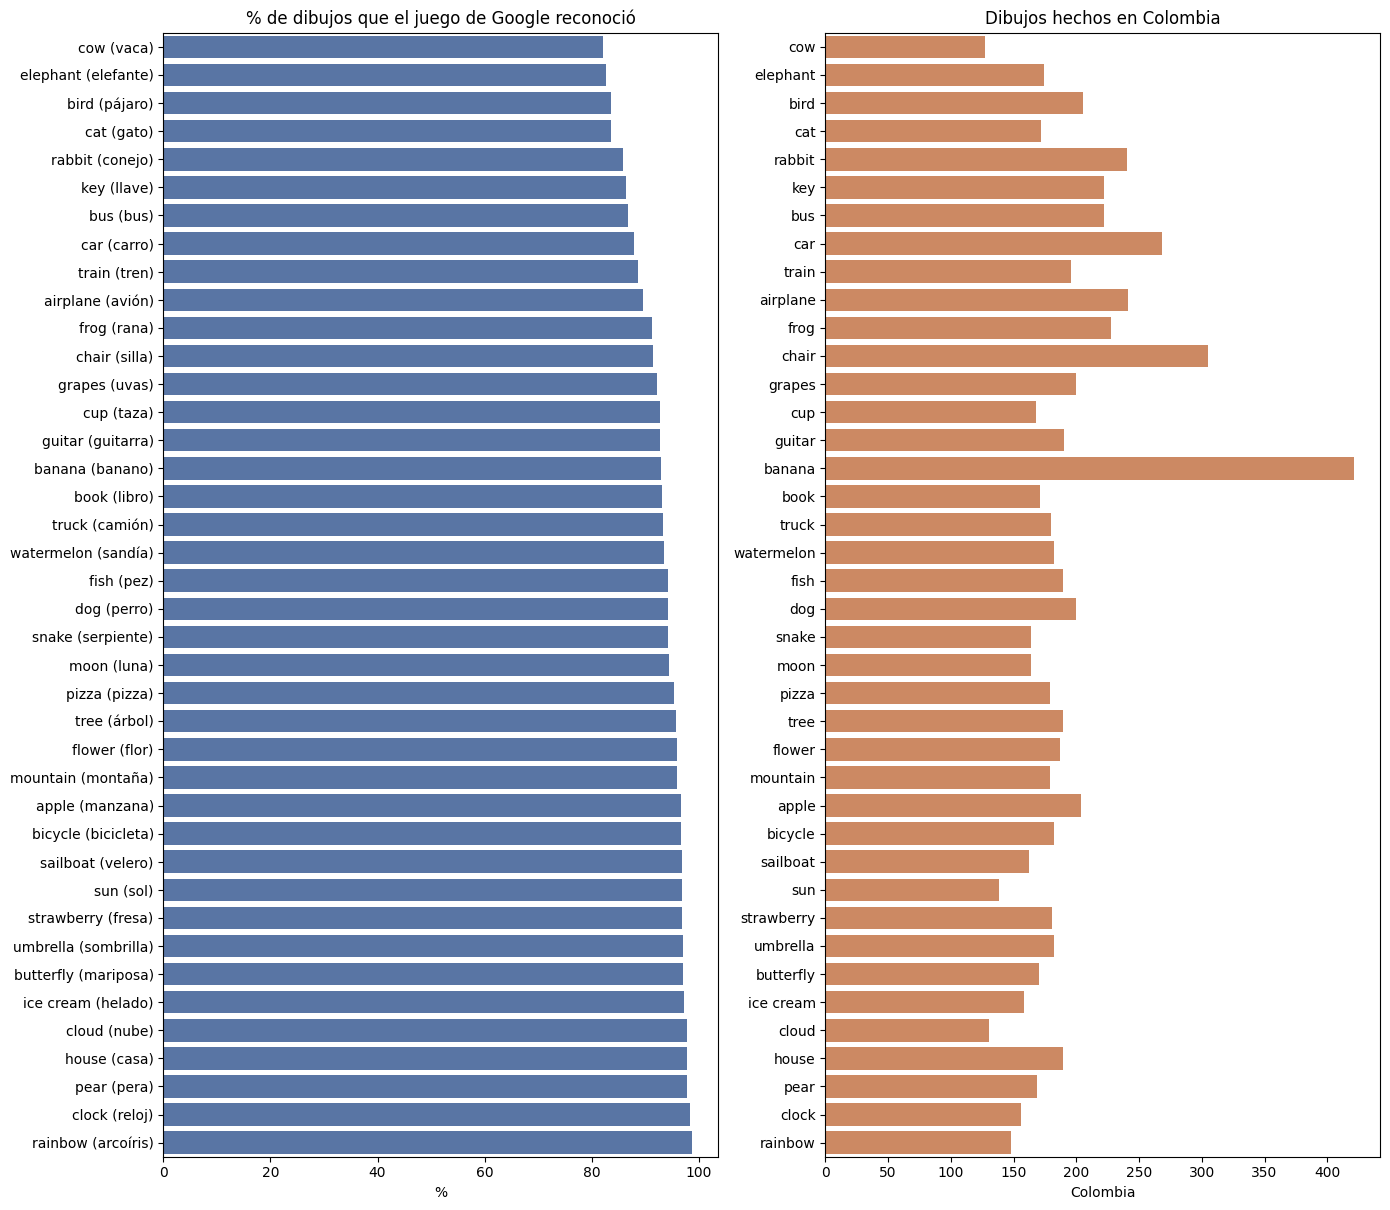

Total de dibujos de Colombia: 7732


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 0.28 * len(CLASES) + 1))
orden = tabla_stats.sort_values("% reconocidos").index
sns.barplot(x=tabla_stats.loc[orden, "% reconocidos"], y=[f"{p} ({PALABRAS[p]})" for p in orden], ax=ax[0], color="#4C72B0")
ax[0].set_title("% de dibujos que el juego de Google reconoció")
ax[0].set_xlabel("%"); ax[0].set_ylabel("")
sns.barplot(x=tabla_stats.loc[orden, "Colombia"], y=[f"{p}" for p in orden], ax=ax[1], color="#DD8452")
ax[1].set_title("Dibujos hechos en Colombia"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
print("Total de dibujos de Colombia:", tabla_stats["Colombia"].sum())

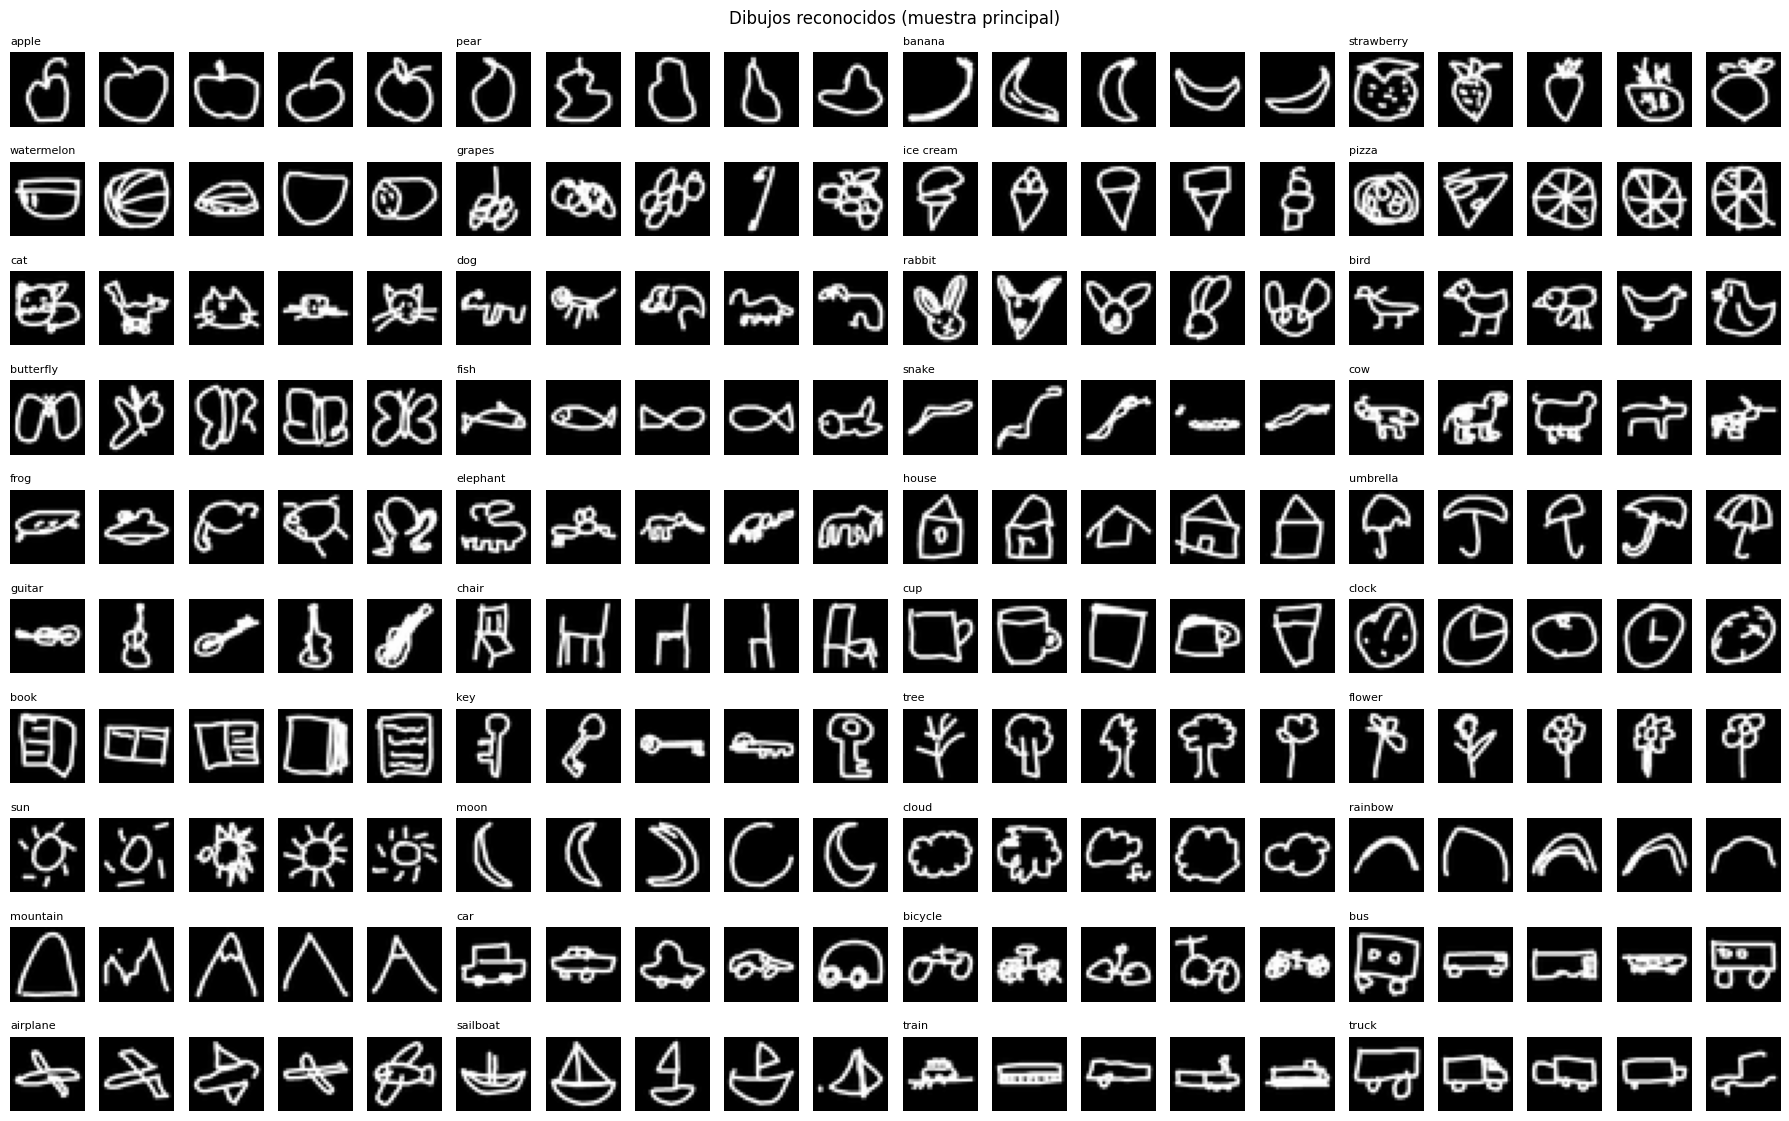

In [7]:
def mostrar(mascara, titulo, por_clase=5, clases_por_fila=4):
    filas = int(np.ceil(len(CLASES) / clases_por_fila))
    fig, axes = plt.subplots(filas, por_clase * clases_por_fila, figsize=(por_clase * clases_por_fila * 0.9, filas * 1.15))
    for ax in axes.flat: ax.axis("off")
    for i, c in enumerate(CLASES):
        f, col0 = divmod(i, clases_por_fila)
        idx = np.where(mascara & (y == i))[0]
        sel = np.random.default_rng(SEED).choice(idx, min(por_clase, len(idx)), replace=False) if len(idx) else []
        for j in range(len(sel)):
            axes[f, col0 * por_clase + j].imshow(X[sel[j]], cmap="gray")
        axes[f, col0 * por_clase].set_title(c, fontsize=8, loc="left")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

mostrar(grupo == "principal", "Dibujos reconocidos (muestra principal)")

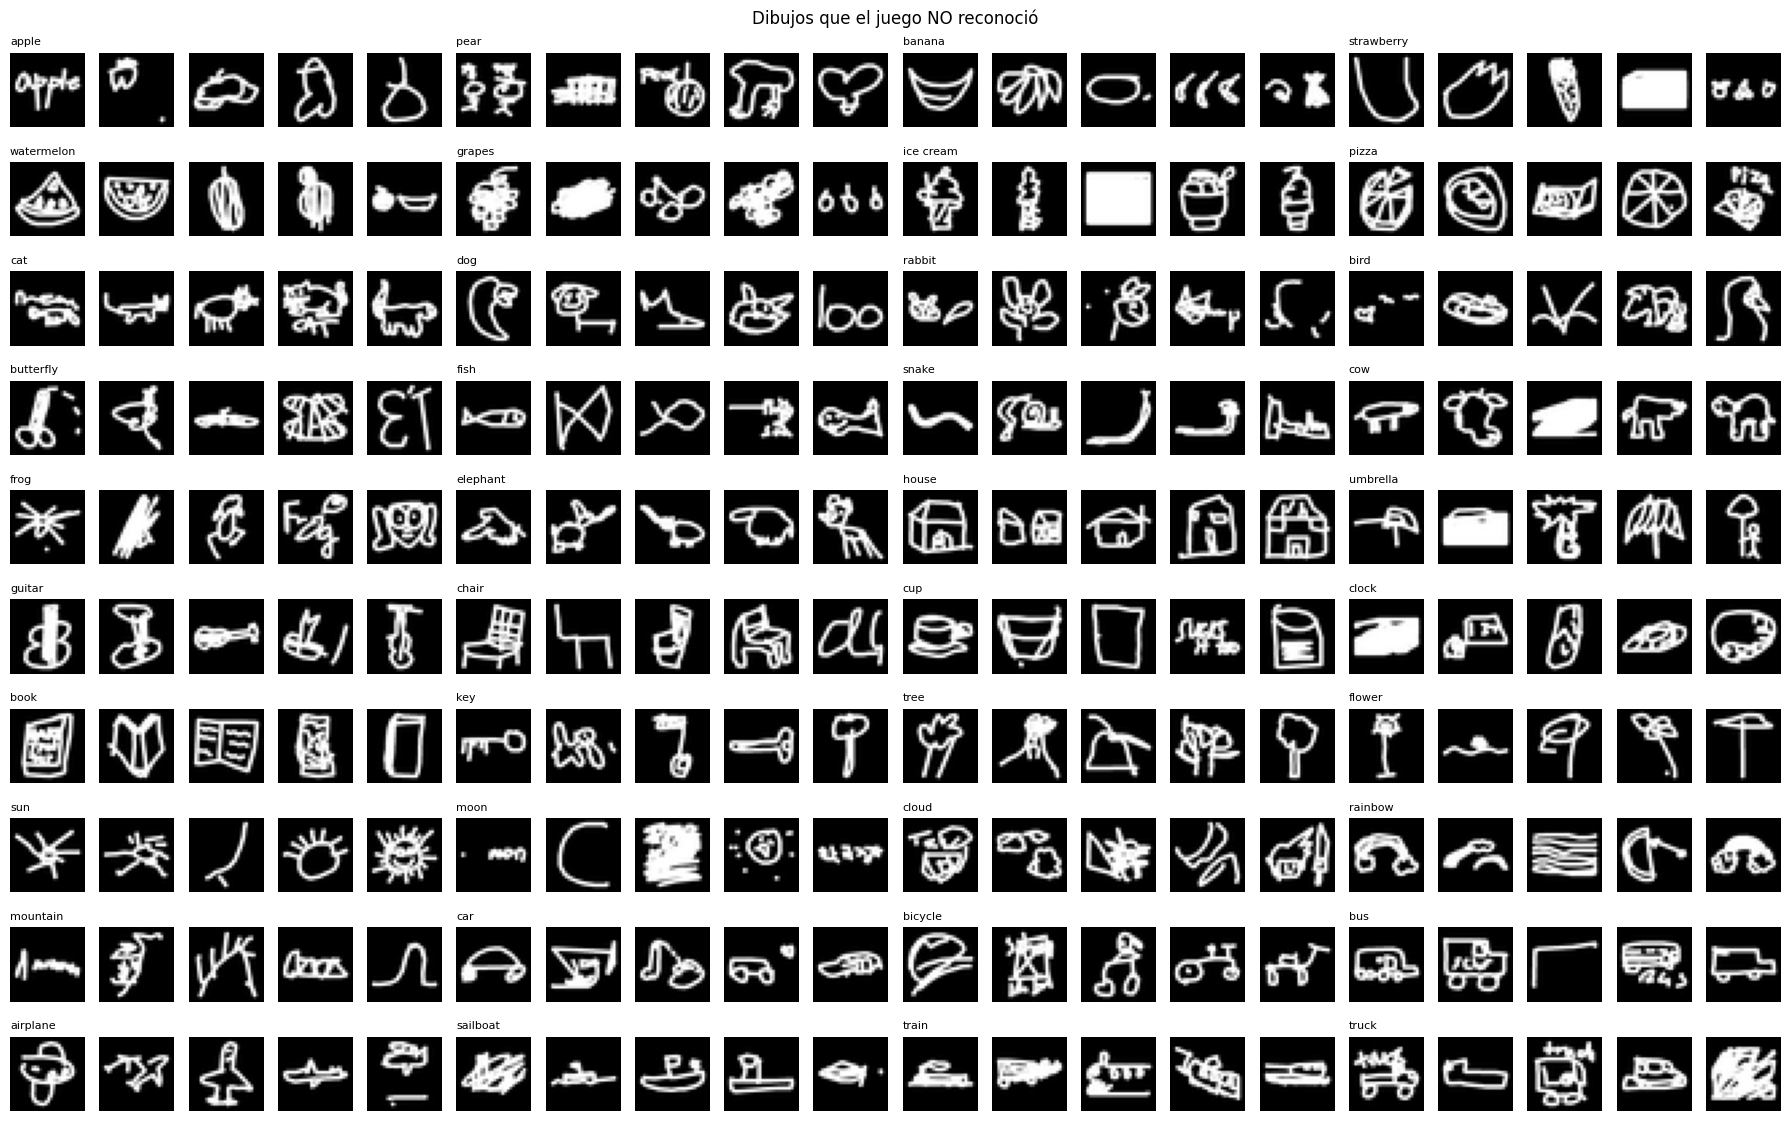

In [8]:
mostrar(grupo == "no_reconocido", "Dibujos que el juego NO reconoció")

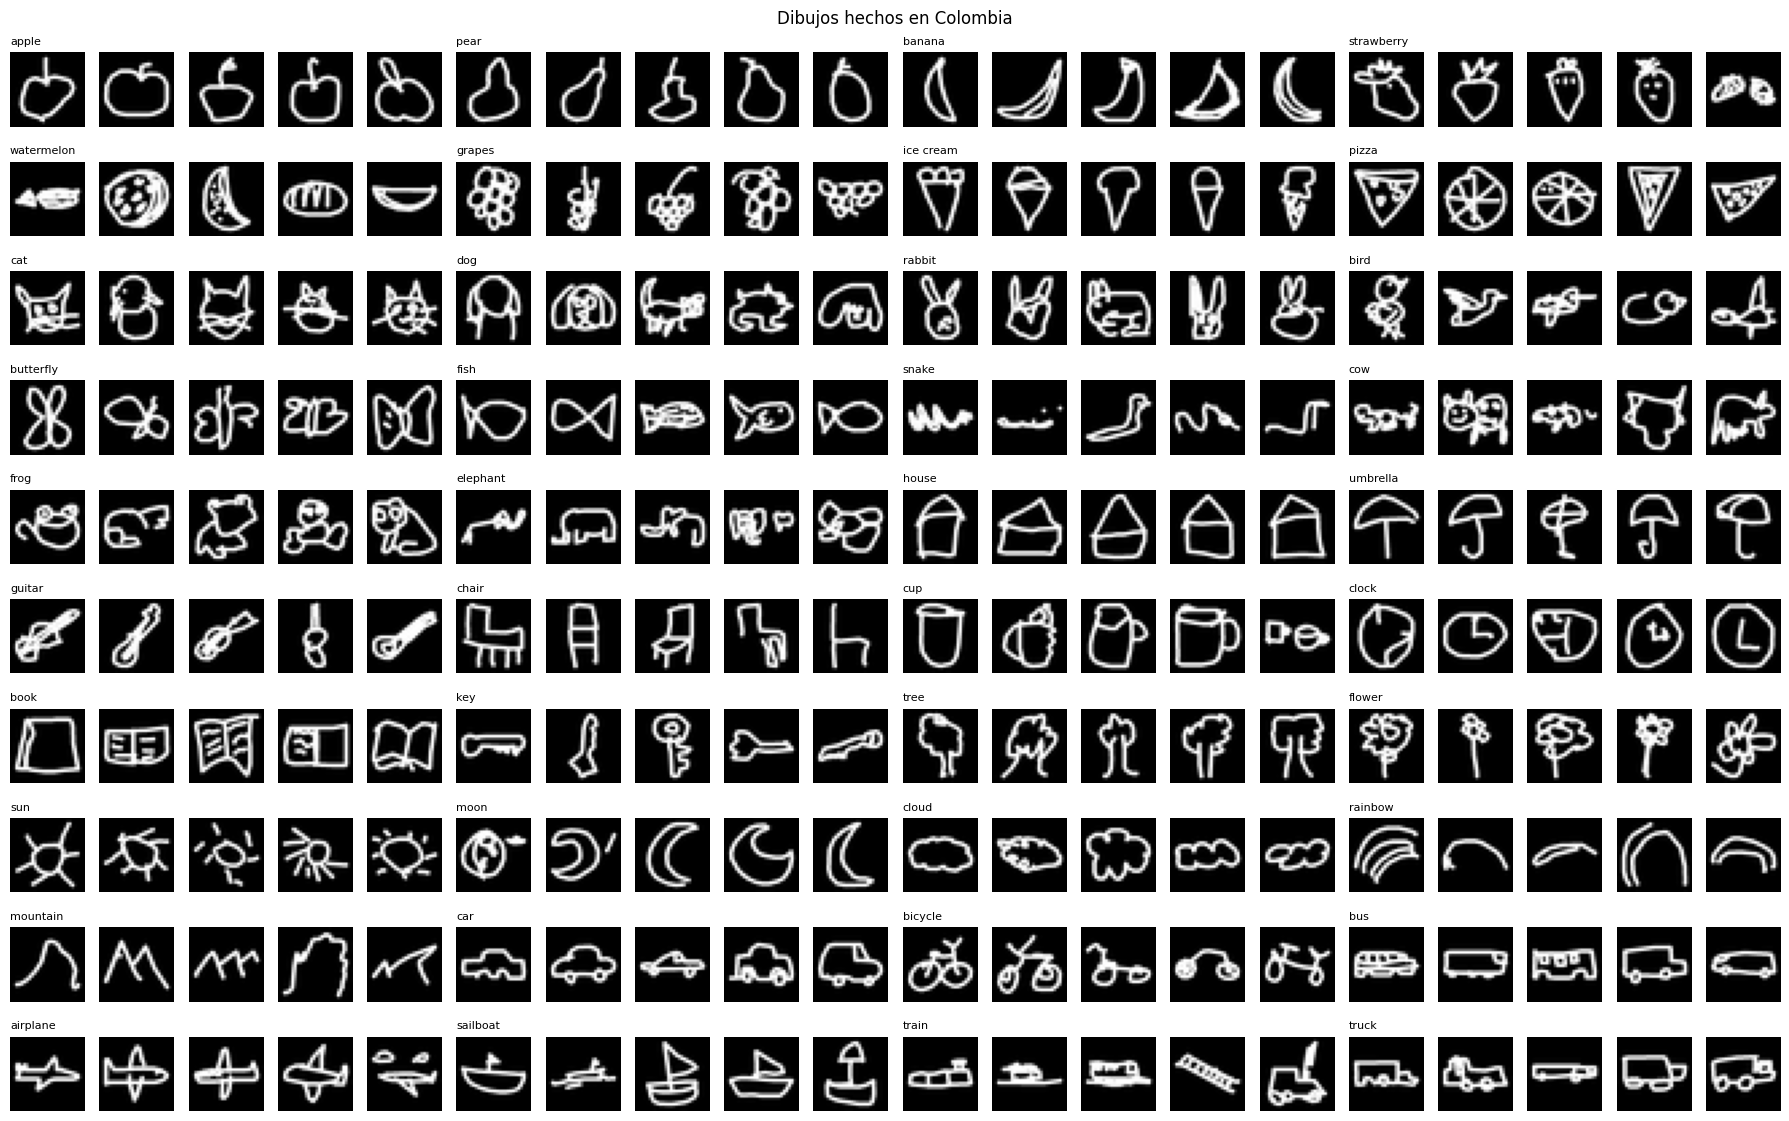

In [9]:
mostrar(np.char.startswith(grupo.astype(str), "colombia"), "Dibujos hechos en Colombia")

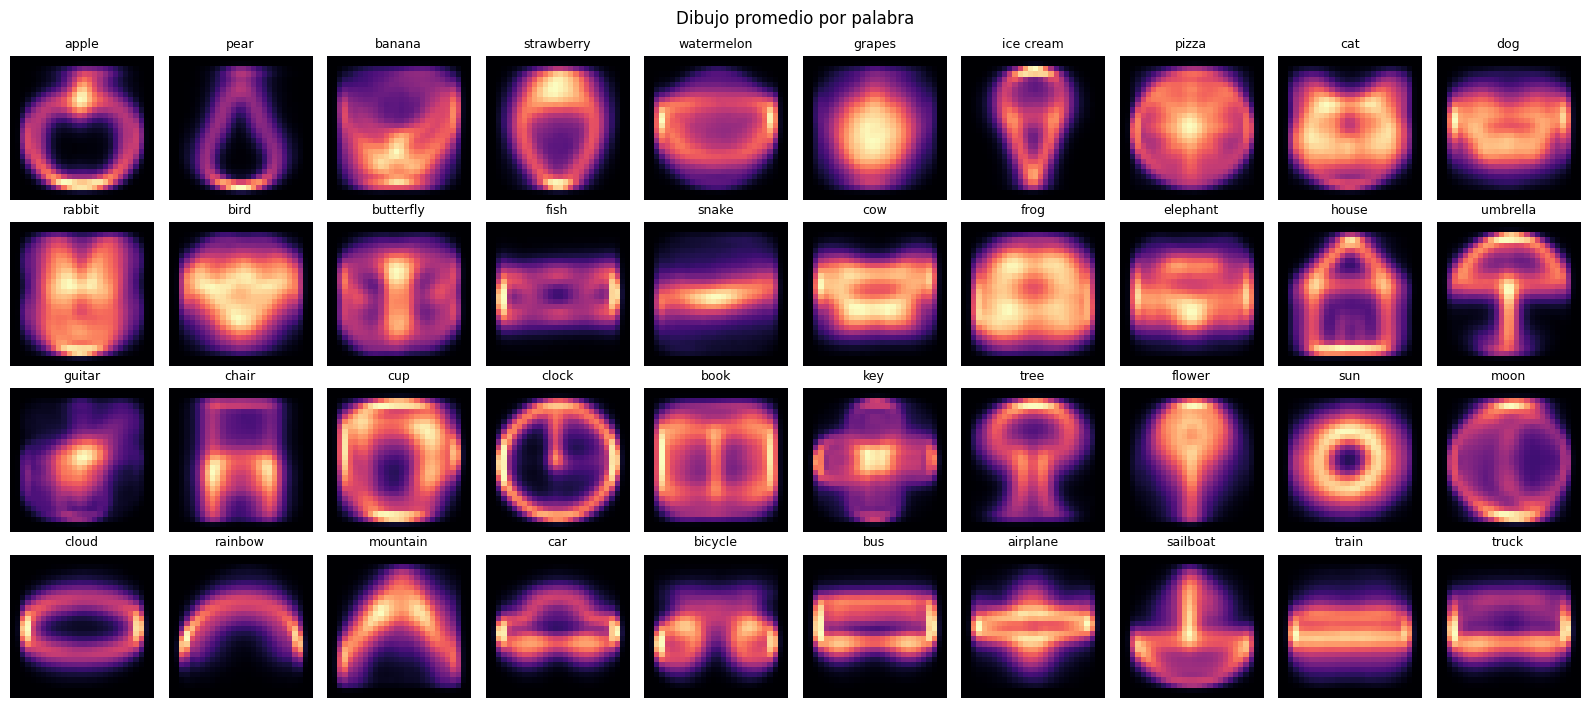

In [10]:
# Dibujo promedio por palabra: muestra la forma "típica" que la gente dibuja
fig, axes = plt.subplots(int(np.ceil(len(CLASES) / 10)), 10, figsize=(16, 1.8 * np.ceil(len(CLASES) / 10)))
for ax in axes.flat: ax.axis("off")
for i, c in enumerate(CLASES):
    ax = axes.flat[i]
    ax.imshow(X[(grupo == "principal") & (y == i)].mean(axis=0), cmap="magma")
    ax.set_title(c, fontsize=9); ax.axis("off")
plt.suptitle("Dibujo promedio por palabra"); plt.tight_layout(); plt.show()

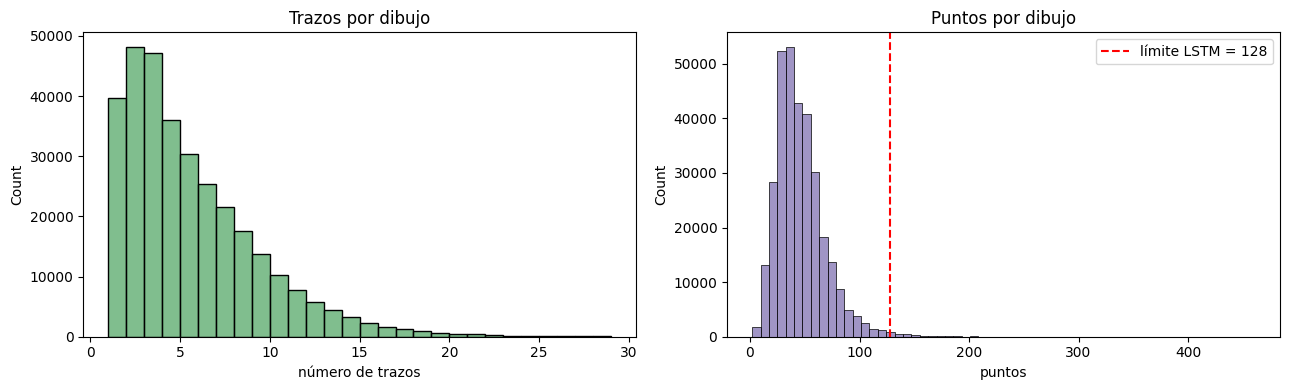

Secuencias recortadas (más de 128 puntos): 0.7 %


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
principal = grupo == "principal"
sns.histplot(n_trazos[principal], bins=range(1, 30), ax=ax[0], color="#55A868")
ax[0].set_title("Trazos por dibujo"); ax[0].set_xlabel("número de trazos")
sns.histplot(largos[principal], bins=60, ax=ax[1], color="#8172B2")
ax[1].axvline(MAX_PUNTOS, color="red", ls="--", label=f"límite LSTM = {MAX_PUNTOS}")
ax[1].set_title("Puntos por dibujo"); ax[1].set_xlabel("puntos"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Secuencias recortadas (más de {MAX_PUNTOS} puntos): {100 * (largos[principal] > MAX_PUNTOS).mean():.1f} %")

## 5. Partición (70/15/15)

Solo la muestra principal se divide en entrenamiento, validación y prueba, estratificado por palabra. Los dibujos de Colombia y los no reconocidos quedan **solo para prueba**: el modelo nunca los ve al entrenar.

In [12]:
idx = np.where(principal)[0]
i_train, i_temp = train_test_split(idx, test_size=0.30, stratify=y[idx], random_state=SEED)
i_val, i_test = train_test_split(i_temp, test_size=0.50, stratify=y[i_temp], random_state=SEED)
i_noreco = np.where(grupo == "no_reconocido")[0]
i_col = np.where(np.char.startswith(grupo.astype(str), "colombia"))[0]

conjuntos = {"train": i_train, "val": i_val, "test": i_test, "no_reconocidos": i_noreco, "colombia": i_col}
resumen = pd.DataFrame({k: np.bincount(y[v], minlength=len(CLASES)) for k, v in conjuntos.items()}, index=CLASES)
resumen.loc["total"] = resumen.sum()
resumen

,train,val,test,no_reconocidos,colombia
apple,5600,1200,1200,1000,204
pear,5600,1200,1200,1000,169
banana,5600,1200,1200,1000,421
strawberry,5600,1200,1200,1000,181
watermelon,5600,1200,1200,1000,182
grapes,5600,1200,1200,1000,200
ice cream,5600,1200,1200,1000,158
pizza,5600,1200,1200,1000,179
cat,5600,1200,1200,1000,172
dog,5600,1200,1200,1000,200


## 6. Guardar

Se guarda todo en un solo archivo comprimido, junto con `dibujos.py` y la lista de palabras. Los siguientes notebooks solo cargan este archivo.

In [13]:
SALIDA = BASE / "dibujos_datos.npz"
guardar = {}
for k, v in conjuntos.items():
    guardar[f"X_{k}"] = X[v]
    guardar[f"S_{k}"] = S[v].astype(np.float16)
    guardar[f"y_{k}"] = y[v]
guardar["colombia_reconocido"] = (grupo[i_col] == "colombia_reco")
np.savez_compressed(SALIDA, **guardar)
with open(BASE / "palabras.json", "w", encoding="utf-8") as f:
    json.dump(PALABRAS, f, ensure_ascii=False, indent=2)
with open(BASE / "temas.json", "w", encoding="utf-8") as f:
    json.dump({t: list(p) for t, p in TEMAS.items()}, f, ensure_ascii=False, indent=2)
tabla_stats.to_csv(BASE / "estadisticas_palabras.csv")
print("Tamaño:", round(os.path.getsize(SALIDA) / 1e6, 1), "MB")

Tamaño: 185.2 MB


In [15]:
GUARDAR_EN_DRIVE = True
if GUARDAR_EN_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    destino = Path("/content/drive/MyDrive/proyecto_dibujos")
    destino.mkdir(parents=True, exist_ok=True)
    for archivo in ["dibujos_datos.npz", "palabras.json", "temas.json", "estadisticas_palabras.csv"]:
        shutil.copy(BASE / archivo, destino)
    shutil.copy("dibujos.py", destino)
    print("Guardado en", destino)

Mounted at /content/drive
Guardado en /content/drive/MyDrive/proyecto_dibujos


## Resumen

*(Completar con los números de la ejecución.)*
- Palabras: 40 en 5 temas. Dibujos reconocidos por palabra: 8.000 → 5.600 / 1.200 / 1.200.
- Dibujos no reconocidos por palabra: hasta 1.000 (prueba difícil).
- Dibujos de Colombia: ___ en total.
- Palabra que la gente dibuja peor (menos reconocida): ___.

**Siguiente paso:** SVM, ANN, CNN y transfer learning.